In [25]:
data_yaml_path = 'dataset/road-mark/data.yaml'
images_dir = 'dataset/road-mark/train/images'
labels_dir = 'dataset/road-mark/train/labels'

In [2]:
import random
import pandas as pd
import cv2
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches

In [12]:
image_files = [f for f in os.listdir(images_dir) if f.endswith('.jpg')]
selected_images = random.sample(image_files, 1)
selected_images

['334b_jpg.rf.87a99e24eb1502a3d2238a92d5059a3e.jpg']

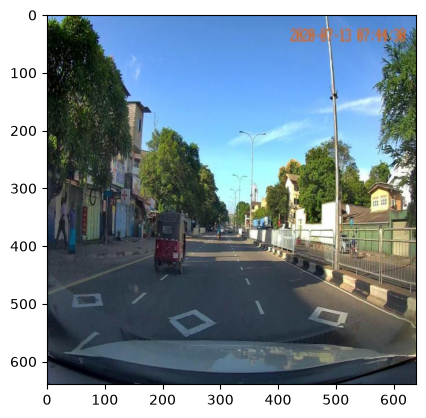

In [13]:
# 指定图片路径
img_path = os.path.join(images_dir, selected_images[0])
image = cv2.imread(img_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)

In [14]:
# 图片对应的 .txt 文件
label_path = os.path.join(labels_dir, selected_images[0].replace('.jpg', '.txt'))
# 读取每行前 11 个元素
df = pd.read_csv(label_path, header = None, sep = ' ', usecols = range(11))
df

,0,1,2,3,4,5,6,7,8,9,10
0,2,0.004630,0.763509,0.004985,0.761609,0.152773,0.705897,0.292726,0.652084,0.291657,0.643222
1,2,0.095794,0.905955,0.147787,0.862905,0.133543,0.855941,0.065169,0.907853,0.095794,0.905955
2,2,0.241445,0.785667,0.278125,0.749581,0.261744,0.746416,0.220434,0.776170,0.241445,0.785667
3,2,0.301629,0.721092,0.298780,0.721092,0.313737,0.722991,0.334035,0.699567,0.325844,0.698933
4,2,0.542718,0.731855,0.554826,0.734386,0.544855,0.710330,0.534528,0.712228,0.542718,0.731855
5,2,0.580466,0.814156,0.592931,0.812891,0.571563,0.769206,0.560524,0.771106,0.580466,0.814156
6,2,0.527422,0.692933,0.534085,0.691856,0.528937,0.679203,0.521819,0.681088,0.527422,0.692933
7,2,0.988306,0.827361,0.917424,0.799009,0.752217,0.715555,0.653388,0.669634,0.591620,0.636094
8,5,0.459596,0.835227,0.403199,0.795455,0.330808,0.822443,0.378788,0.873580,0.459596,0.835227
9,5,0.153199,0.786932,0.145623,0.755682,0.073232,0.754261,0.069865,0.795455,0.153199,0.786932


In [15]:
image_height, image_width, _ = image.shape
print('image_height:', image_height)
print('image_width:', image_width)

image_height: 640
image_width: 640


In [16]:
# 获取第 1 行 2 ～ 5 列数据
bb = df.iloc[0, 1:5].tolist()
bb

[0.004629629687499999, 0.763509375, 0.0049851859375, 0.761609375]

In [17]:
def plot_rectangle(bb):
    # 列表各元素乘以 640
    bb_scaled = [coord * 640 for coord in bb]
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    width = bb_scaled[2] - bb_scaled[0]
    height = bb_scaled[3] - bb_scaled[1]
    # 创建一个矩形补丁
    rect = patches.Rectangle((bb_scaled[0], bb_scaled[1]), width, height, linewidth = 2, edgecolor = 'r', facecolor = 'none')
    # 添加矩形到图片
    ax.add_patch(rect)
    # 显示图像
    plt.show()

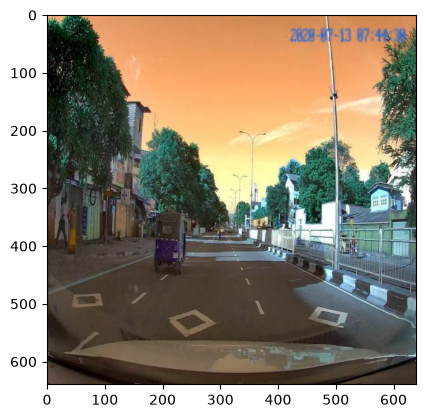

In [18]:
plot_rectangle(bb)

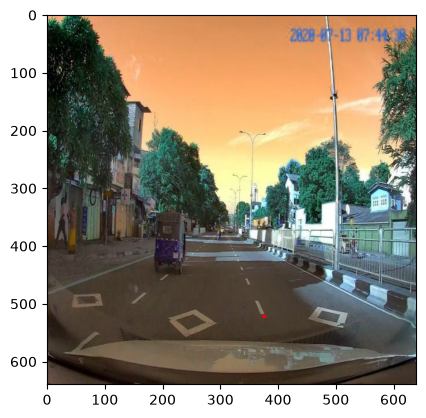

In [19]:
# 获取第 6 行第 2 ～ 5 列数据
bb = df.iloc[5, 1:5].tolist()
# 可视化
plot_rectangle(bb)

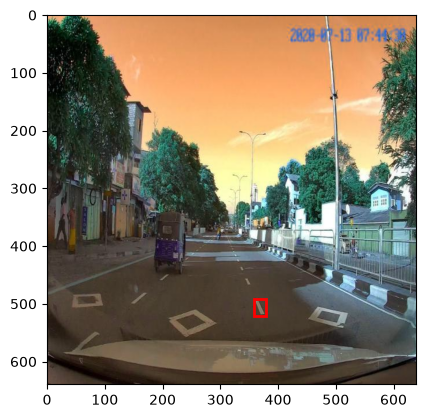

In [21]:
bb1 = [0.560524, 0.769206, 0.592931, 0.814156]
plot_rectangle(bb1)

In [30]:
def label_change(label_dir):
    """
    根据给定的标签路径，读取并处理对应的标签文件

    参数：
    label_dir (str): 标签文件的路径

    返回：
    list: 包含处理后的标签信息的列表，每个元素是一个字典，包含 'id' 和 'bb' 两个键
    """
    # 更新 label_dir 为特定 labels 目录和选定图片对应的 .txt 文件
    label_path = os.path.join(labels_dir, selected_images[0].replace('.jpg', '.txt'))

    # 读取 .txt 文件到 DataFrame 中
    # 根据实际情况调整 sep 参数
    df = pd.read_csv(label_path, header = None, sep = ' ', usecols = range(11))

    # 初始化结果列表
    results = []

    # 遍历每一行数据进行处理
    for index, row in df.iterrows():
        # 第 0 列作为 id
        id_value = int(row[0])

        # 获取并计算 x 坐标（偶数列）的最小值和最大值
        even_cols = row.loc[1:9:2]
        x_min = even_cols.min()
        x_max = even_cols.max()

        # 获取并计算 y 坐标（奇数列）的最小值和最大值
        odd_cols = row.loc[2:10:2]
        y_min = odd_cols.min()
        y_max = odd_cols.max()

        # 构建边界框列表
        bb = [x_min, y_min, x_max, y_max]

        # 将处理后的信息添加到结果列表中
        results.append({
            'id': id_value,
            'bb': bb
        })

    # 返回处理后的结果
    return results

In [31]:
results = label_change(labels_dir)
results

[{'id': 2,
  'bb': [np.float64(0.004629629687499999),
   np.float64(0.6432218749999999),
   np.float64(0.2927259265625),
   np.float64(0.763509375)]},
 {'id': 2,
  'bb': [np.float64(0.06516851875),
   np.float64(0.855940625),
   np.float64(0.1477870375),
   np.float64(0.9078531249999999)]},
 {'id': 2,
  'bb': [np.float64(0.220434259375),
   np.float64(0.746415625),
   np.float64(0.278125),
   np.float64(0.7856671875)]},
 {'id': 2,
  'bb': [np.float64(0.2987796296875),
   np.float64(0.6989328125000001),
   np.float64(0.33403518593750003),
   np.float64(0.722990625)]},
 {'id': 2,
  'bb': [np.float64(0.534527778125),
   np.float64(0.7103296875),
   np.float64(0.5548259265625),
   np.float64(0.7343859375)]},
 {'id': 2,
  'bb': [np.float64(0.5605240734375),
   np.float64(0.76920625),
   np.float64(0.59293055625),
   np.float64(0.8141562499999999)]},
 {'id': 2,
  'bb': [np.float64(0.52181944375),
   np.float64(0.679203125),
   np.float64(0.5340851859375),
   np.float64(0.6929328124999999)]},

In [36]:
def plot_rectangle(img_dir, results):
    """
    给指定的图片上绘制矩形框和相应的 id

    参数：
    img_dir (str): 图片文件的路径
    results (list): 包含边界框和 id 信息的列表，每个元素是一个字典，包含 "bb" 和 "id" 键
    """
    # 指定图片路径
    img_path = os.path.join(images_dir, selected_images[0])
    # 读取图片文件并显示
    image = plt.imread(img_path)
    fig, ax = plt.subplots(1)
    ax.imshow(image)

    # 在图片上绘制边界框及 id
    for result in results:
        # 根据结果中的边界框信息，进行缩放以匹配图片的尺寸
        bb_scaled = [coord * 640 for coord in result['bb']]
        # 计算边界框的宽度和高度
        width = bb_scaled[2] - bb_scaled[0]
        height = bb_scaled[3] - bb_scaled[1]

        # 创建一个矩形补丁
        rect = patches.Rectangle((bb_scaled[0], bb_scaled[1]), width, height, linewidth = 2, edgecolor = 'r', facecolor = 'none')

        # 添加矩形到图片
        ax.add_patch(rect)

        # 在图片上添加文本
        plt.text(bb_scaled[0], bb_scaled[1], str(result['id']), color = 'white', fontsize = 12, verticalalignment = 'top')

    # 显示图片
    plt.show()

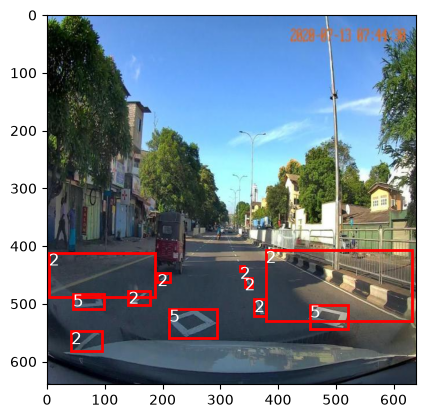

In [37]:
plot_rectangle(images_dir, results)

875a_jpg.rf.f8708a3ab470d6af8b5d5d19ef530a54.jpg


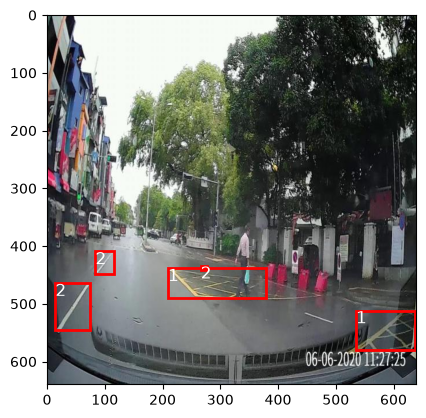

542a_jpg.rf.87046037aa7bb417894b6acbd4971f5e.jpg


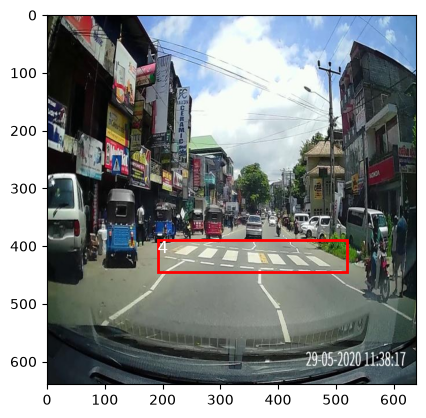

In [38]:
# 随机抽取 2 张图片进行标注
multi_images = random.sample(image_files, 2)
for i in [0, 1]:
    # 选取图片
    selected_images = [multi_images[i]]
    # 查看图片名称
    print(selected_images[0])
    # 得到新的边界框坐标
    results = label_change(labels_dir)
    # 对图片绘制边框及对应的 ID
    plot_rectangle(images_dir, results)

In [59]:
def process_text_file(file_path):
    """
    处理文本文件，提取边界框信息

    从指定的文本文件中读取数据，每行数据的第一个元素作为 id，后续成对的浮点数表示边界框的坐标
    计算每个边界框的最小 x 坐标、最大 x 坐标、最小 y 坐标和最大 y 坐标，并存储这些信息

    参数：
    - file_path: str, 文本文件的路径

    返回：
    - ids: List[str]，提取的 id 列表
    - bbs: List[List[float]]，提取的边界框坐标列表，每个边界框由 [x_min, y_min, width, height] 表示
    - line_lengths: List[int], 每行数据中坐标值的数量列表
    """
    ids = []
    bbs = []
    line_lengths = []

    with open(file_path, 'r') as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) > 0:
                id_value = parts[0]
                values = list(map(float, parts[1:]))

                even_values = values[::2]
                odd_values = values[1::2]

                x_min = min(even_values)
                x_max = max(even_values)
                y_min = min(odd_values)
                y_max = max(odd_values)

                bb = [x_min, y_min, x_max - x_min, y_max - y_min]

                bbs.append(bb)
                ids.append(id_value)
                line_lengths.append(len(values))

    return ids, bbs, line_lengths

In [60]:
from PIL import Image
def plot_image_with_bounding_boxes(image_path, ids, bbs, line_lengths, scale_factor = 640):
    """
    绘制带有边界框的图片

    加载图片并在其上绘制边界框和相关 id 及坐标数量信息

    参数：
    - image_path: str, 图片文件路径
    - ids: List[str], 边界框的 id 列表
    - bbs: List[List[float]], 边界框坐标列表
    - line_lengths: List[int], 每行数据中坐标值的数量列表
    - scale_factor: int, 缩放因子，默认是 640
    """
    # 加载图片
    image = Image.open(image_path)

    # 绘制图片和边界框
    fig, ax = plt.subplots(figsize = (8, 8))
    ax.imshow(image)

    # 绘制每个边界框
    for i, (bb, id_value, length) in enumerate(zip(bbs, ids, line_lengths)):
        rect = patches.Rectangle((bb[0] * scale_factor, bb[1] * scale_factor), bb[2] * scale_factor, bb[3] * scale_factor, linewidth = 2, edgecolor = 'r', facecolor = 'none')
        ax.add_patch(rect)
        ax.text(bb[0] * scale_factor, bb[1] * scale_factor, f"{id_value}({length})", verticalalignment = 'bottom', color = 'white', fontsize = 10, weight = 'bold')

    plt.axis('off')
    plt.show()

In [61]:
# 调用
text_file_path = 'dataset/road-mark/train/labels/52_jpg.rf.6c38e2667639c8e1c3dcb6b4ab3fc695.txt'
image_file_path = 'dataset/road-mark/train/images/52_jpg.rf.6c38e2667639c8e1c3dcb6b4ab3fc695.jpg'

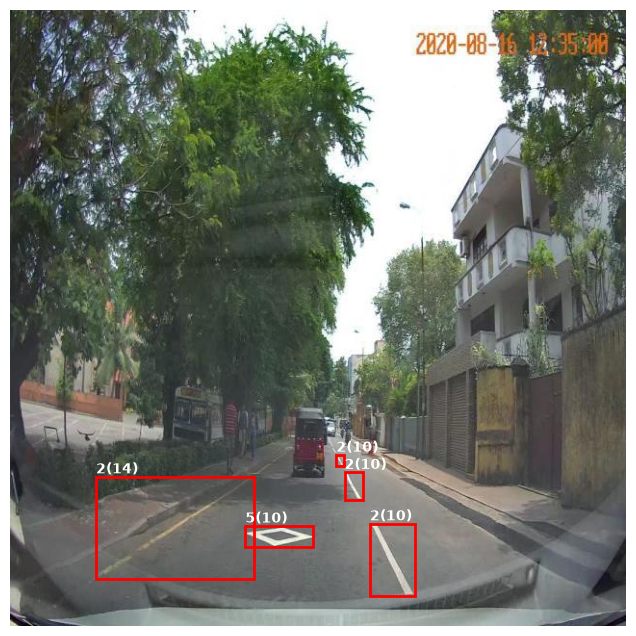

In [63]:
ids, bbs, line_lengths = process_text_file(text_file_path)
# ids
plot_image_with_bounding_boxes(image_file_path, ids, bbs, line_lengths)